Число точек: 150; seed: 42


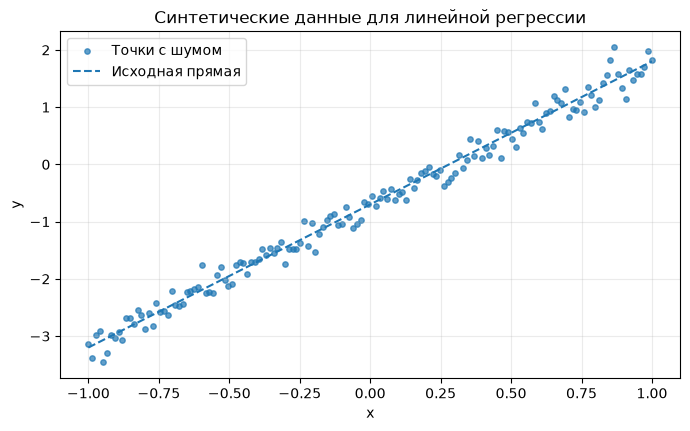

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

SEED = 42
rng = np.random.default_rng(SEED)

n = 150
x = np.linspace(-1.0, 1.0, n)
true_w, true_b = 2.5, -0.7
noise = rng.normal(loc=0.0, scale=0.2, size=n)
y = true_w * x + true_b + noise

print(f"Число точек: {n}; seed: {SEED}")

plt.figure(figsize=(8, 4.5))
plt.scatter(x, y, s=15, alpha=0.7, label="Точки с шумом")
plt.plot(x, true_w * x + true_b, linestyle="--", label="Исходная прямая")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Синтетические данные для линейной регрессии")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 2. Реализация градиентного спуска на NumPy

В каждом шаге считаются предсказания, MSE и производные функции ошибки. Алгоритм записывает параметры и MSE после обновления весов, поэтому длина истории — `iterations + 1`.

In [16]:
def gradient_descent(x, y, learning_rate, iterations=250, w0=0.0, b0=0.0):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    w, b = float(w0), float(b0)
    mse_history = []
    parameter_history = []

    for step in range(iterations + 1):
        predictions = w * x + b
        error = predictions - y
        mse = np.mean(error ** 2)
        mse_history.append(float(mse))
        parameter_history.append((w, b))

        if step == iterations:
            break

        dw = 2.0 * np.mean(error * x)
        db = 2.0 * np.mean(error)
        w -= learning_rate * dw
        b -= learning_rate * db

    return w, b, np.array(mse_history), np.array(parameter_history)

rates = [0.005, 0.03, 0.1, 1.2]
iterations = 250
runs = {alpha: gradient_descent(x, y, alpha, iterations) for alpha in rates}

for alpha, (w, b, errors, _) in runs.items():
    print(f"alpha={alpha:<5} w={w:>14.6g}  b={b:>14.6g}  MSE={errors[-1]:.6g}")

alpha=0.005 w=       1.41723  b=     -0.652557  MSE=0.415774
alpha=0.03  w=       2.46782  b=     -0.710118  MSE=0.0290707
alpha=0.1   w=       2.48267  b=     -0.710118  MSE=0.0289962
alpha=1.2   w=  -2.01899e+20  b=   2.41735e+36  MSE=5.84358e+72


## 3. Сравнение MSE при четырёх скоростях обучения

Используется логарифмическая шкала по оси MSE, потому что при $\alpha=1.2$ ошибка быстро возрастает на много порядков. Это показывает **расходимость**, а не ошибку построения графика.

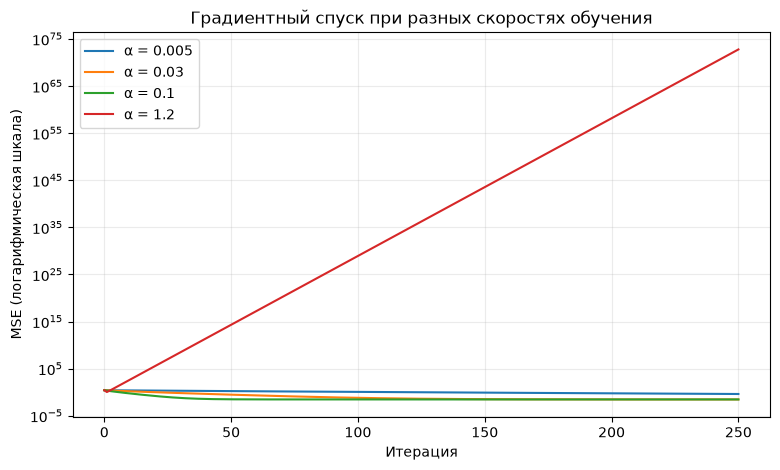

Проверка пройдена: α=0.1 сходится, α=1.2 расходится.


In [3]:
plt.figure(figsize=(9, 5))
for alpha, (_, _, errors, _) in runs.items():
    plt.semilogy(np.arange(len(errors)), errors, label=f"α = {alpha}")
plt.xlabel("Итерация")
plt.ylabel("MSE (логарифмическая шкала)")
plt.title("Градиентный спуск при разных скоростях обучения")
plt.legend()
plt.grid(alpha=0.25, which="both")
plt.show()

assert runs[1.2][2][-1] > runs[1.2][2][0], "Ожидалась расходимость при α=1.2"
assert runs[0.1][2][-1] < runs[0.1][2][0], "Ожидалось уменьшение ошибки при α=0.1"
print("Проверка пройдена: α=0.1 сходится, α=1.2 расходится.")

## 4. Сравнение с LinearRegression

`LinearRegression` находит параметры линейной модели без нашего итеративного градиентного спуска. Сравниваем с ним самый удачный эксперимент ($\alpha=0.1$).

LinearRegression : w=2.48266902, b=-0.71011788
Gradient descent: w=2.48266896, b=-0.71011788
Разница по w: 6.3090738e-08
Разница по b: 2.220446e-16


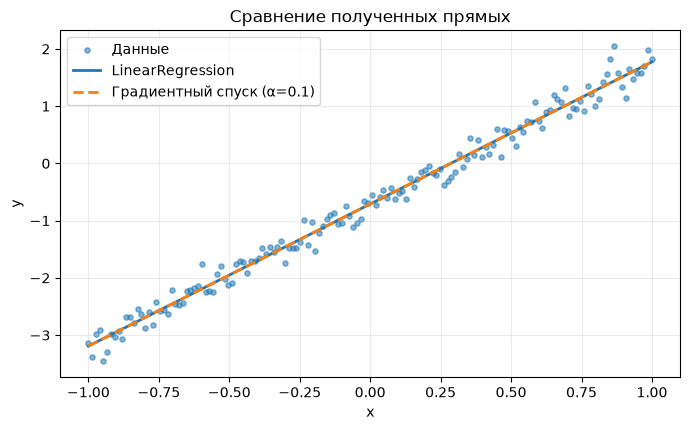

In [4]:
reference = LinearRegression()
reference.fit(x.reshape(-1, 1), y)
w_ref = float(reference.coef_[0])
b_ref = float(reference.intercept_)

w_gd, b_gd, mse_gd, _ = runs[0.1]
print(f"LinearRegression : w={w_ref:.8f}, b={b_ref:.8f}")
print(f"Gradient descent: w={w_gd:.8f}, b={b_gd:.8f}")
print(f"Разница по w: {abs(w_gd - w_ref):.8g}")
print(f"Разница по b: {abs(b_gd - b_ref):.8g}")

assert np.isclose(w_gd, w_ref, atol=1e-5)
assert np.isclose(b_gd, b_ref, atol=1e-5)

plt.figure(figsize=(8, 4.5))
plt.scatter(x, y, s=14, alpha=0.55, label="Данные")
plt.plot(x, reference.predict(x.reshape(-1, 1)), label="LinearRegression", linewidth=2)
plt.plot(x, w_gd * x + b_gd, linestyle="--", label="Градиентный спуск (α=0.1)", linewidth=2)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Сравнение полученных прямых")
plt.grid(alpha=0.25)
plt.legend()
plt.show()

## 5. Вывод

Для небольших значений скорости обучения MSE уменьшается, но при `α=0.005` процесс идёт медленно. При `α=0.1` за 250 итераций параметры практически совпадают с результатом `LinearRegression`. При `α=1.2` MSE растёт, поэтому градиентный спуск расходится.
